# Tarea 15 — DGIM

**Pregunta:** ¿Cuántos de los últimos W procesos publicados fueron declarados desiertos?

Cada proceso se representa como un bit:

- `1`: estado `DESIERTO`
- `0`: cualquier otro estado

DGIM se utilizará para estimar el número de unos en ventanas recientes sin almacenar todos los eventos.

In [1]:
from pathlib import Path
from collections import deque
import math
import time

import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F

In [2]:
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("SEACE-DGIM")
    .config("spark.driver.memory", "8g")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

PROJECT_ROOT = Path.home() / "dm"
DATA_DIR = PROJECT_ROOT / "parquet"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts" / "dgim"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

26/10/04 20:48:35 WARN Utils: Your hostname, willian-pc resolves to a loopback address: 127.0.1.1; using 192.168.18.28 instead (on interface wlo1)
26/10/04 20:48:35 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/04 20:48:35 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/04 20:48:36 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/10/04 20:48:36 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/10/04 20:48:36 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/10/04 20:48:36 WARN Utils: Service 'SparkUI' could not bind on port 4043. Attempting port 4044.


In [3]:
procesos = spark.read.parquet(
    str(DATA_DIR / "procesos")
)

stream_procesos = (
    procesos
    .select(
        "fecha_pub",
        "release_id",
        "estado_proceso"
    )
    .withColumn(
        "es_desierto",
        (F.col("estado_proceso") == "DESIERTO").cast("int")
    )
    .orderBy(
        "fecha_pub",
        "release_id"
    )
)

In [4]:
class DGIM:
    def __init__(self, window_size):
        if window_size <= 0:
            raise ValueError("window_size debe ser positivo")

        self.window_size = int(window_size)
        self.timestamp = 0

        # (size, end_timestamp), más nuevo primero
        self.buckets = []

    def update(self, bit):
        self.timestamp += 1

        if bit not in (0, 1):
            raise ValueError("bit debe ser 0 o 1")

        if bit == 1:
            self.buckets.insert(
                0,
                (1, self.timestamp)
            )

            self._compress()

        self._expire()

    def _compress(self):
        size = 1

        while True:
            indices = [
                i
                for i, (bucket_size, _) in enumerate(self.buckets)
                if bucket_size == size
            ]

            if len(indices) <= 2:
                # Puede haber buckets mayores que necesiten revisión
                if not any(
                    bucket_size > size
                    for bucket_size, _ in self.buckets
                ):
                    break

                size *= 2
                continue

            # Los dos más antiguos de ese tamaño
            idx_newer = indices[-2]
            idx_older = indices[-1]

            _, end_timestamp = self.buckets[idx_newer]

            self.buckets[idx_newer] = (
                size * 2,
                end_timestamp
            )

            del self.buckets[idx_older]

            size *= 2

    def _expire(self):
        cutoff = self.timestamp - self.window_size

        self.buckets = [
            bucket
            for bucket in self.buckets
            if bucket[1] > cutoff
        ]

    def query(self, k=None):
        if k is None:
            k = self.window_size

        if k <= 0 or k > self.window_size:
            raise ValueError(
                "k debe estar entre 1 y window_size"
            )

        cutoff = self.timestamp - k

        incluidos = [
            (size, end)
            for size, end in self.buckets
            if end > cutoff
        ]

        if not incluidos:
            return 0

        total = sum(
            size
            for size, _ in incluidos
        )

        # El bucket más antiguo se estima a la mitad
        oldest_size = incluidos[-1][0]

        return total - oldest_size + oldest_size / 2

    @property
    def n_buckets(self):
        return len(self.buckets)

In [5]:
dgim_test = DGIM(window_size=10)

bits_test = [
    1, 0, 1, 1, 0,
    0, 1, 0, 1, 1
]

for bit in bits_test:
    dgim_test.update(bit)

print("Conteo exacto:", sum(bits_test))
print("Estimación DGIM:", dgim_test.query(10))
print("Buckets:", dgim_test.buckets)
print("Número de buckets:", dgim_test.n_buckets)

Conteo exacto: 6
Estimación DGIM: 5.0
Buckets: [(1, 10), (1, 9), (2, 7), (2, 3)]
Número de buckets: 4


In [6]:
bits = [
    row["es_desierto"]
    for row in stream_procesos.select(
        "es_desierto"
    ).toLocalIterator()
]

print("Eventos:", len(bits))
print("Desiertos:", sum(bits))

Eventos: 209740
Desiertos: 25268


In [7]:
def evaluar_dgim(bits, window_size, sample_every=1000):
    dgim = DGIM(window_size)

    ventana = deque()
    conteo_exacto = 0

    errores_abs = []
    errores_rel = []

    max_buckets = 0

    inicio = time.perf_counter()

    for t, bit in enumerate(bits, start=1):
        dgim.update(bit)

        ventana.append(bit)
        conteo_exacto += bit

        if len(ventana) > window_size:
            conteo_exacto -= ventana.popleft()

        max_buckets = max(
            max_buckets,
            dgim.n_buckets
        )

        if (
            t >= window_size
            and (t % sample_every == 0 or t == len(bits))
        ):
            estimado = dgim.query(window_size)

            error_abs = abs(
                estimado - conteo_exacto
            )

            errores_abs.append(error_abs)

            if conteo_exacto > 0:
                errores_rel.append(
                    error_abs / conteo_exacto
                )

    tiempo = time.perf_counter() - inicio

    estimacion_final = dgim.query(window_size)

    timestamp_bits = math.ceil(
        math.log2(len(bits) + 1)
    )

    size_bits = max(
        1,
        math.ceil(
            math.log2(
                math.floor(
                    math.log2(window_size)
                ) + 1
            )
        )
    )

    memoria_teorica_bytes = (
        max_buckets
        * (timestamp_bits + size_bits)
        / 8
    )

    return {
        "window_size": window_size,
        "exacto_final": conteo_exacto,
        "estimado_final": estimacion_final,
        "error_final": abs(
            estimacion_final - conteo_exacto
        ),
        "mae": sum(errores_abs) / len(errores_abs),
        "error_rel_pct": (
            sum(errores_rel)
            / len(errores_rel)
            * 100
        ),
        "max_error": max(errores_abs),
        "buckets_final": dgim.n_buckets,
        "max_buckets": max_buckets,
        "memoria_teorica_bytes": memoria_teorica_bytes,
        "tiempo_s": tiempo,
    }

In [8]:
resultados_dgim = []

for window in [
    100,
    500,
    1000,
    5000,
    10000,
    50000,
]:

    r = evaluar_dgim(
        bits,
        window_size=window,
        sample_every=1000
    )

    resultados_dgim.append(r)

    print(
        f"W={window:5d} | "
        f"exacto={r['exacto_final']:6d} | "
        f"estimado={r['estimado_final']:7.1f} | "
        f"MAE={r['mae']:.2f} | "
        f"error rel={r['error_rel_pct']:.2f}% | "
        f"max error={r['max_error']:.1f} | "
        f"max buckets={r['max_buckets']:2d} | "
        f"mem≈{r['memoria_teorica_bytes']:.1f} B | "
        f"tiempo={r['tiempo_s']:.2f}s"
    )

W=  100 | exacto=     0 | estimado=    0.0 | MAE=1.42 | error rel=12.11% | max error=5.0 | max buckets= 8 | mem≈21.0 B | tiempo=0.25s
W=  500 | exacto=     0 | estimado=    0.0 | MAE=6.27 | error rel=10.19% | max error=16.0 | max buckets=12 | mem≈33.0 B | tiempo=0.31s
W= 1000 | exacto=     8 | estimado=    6.0 | MAE=13.73 | error rel=11.60% | max error=38.0 | max buckets=14 | mem≈38.5 B | tiempo=0.36s
W= 5000 | exacto=   208 | estimado=  244.0 | MAE=63.16 | error rel=10.56% | max error=227.0 | max buckets=18 | mem≈49.5 B | tiempo=0.46s
W=10000 | exacto=   785 | estimado=  948.0 | MAE=132.15 | error rel=10.91% | max error=495.0 | max buckets=20 | mem≈55.0 B | tiempo=0.55s
W=50000 | exacto=  6069 | estimado= 6836.0 | MAE=574.73 | error rel=9.25% | max error=1948.0 | max buckets=24 | mem≈66.0 B | tiempo=0.67s


In [9]:
resultados_dgim_pd = pd.DataFrame(
    resultados_dgim
)

resultados_dgim_pd.to_csv(
    ARTIFACTS_DIR / "dgim_ventanas.csv",
    index=False
)

resultados_dgim_pd

,window_size,exacto_final,estimado_final,error_final,mae,error_rel_pct,max_error,buckets_final,max_buckets,memoria_teorica_bytes,tiempo_s
0,100,0,0.0,0.0,1.423810,12.111795,5.0,0,8,21.0,0.253945
1,500,0,0.0,0.0,6.266667,10.186658,16.0,0,12,33.0,0.310928
2,1000,8,6.0,2.0,13.728571,11.603007,38.0,4,14,38.5,0.358884
3,5000,208,244.0,36.0,63.155340,10.560842,227.0,12,18,49.5,0.463605
4,10000,785,948.0,163.0,132.154229,10.913967,495.0,15,20,55.0,0.551057
5,50000,6069,6836.0,767.0,574.726708,9.252521,1948.0,19,24,66.0,0.670323


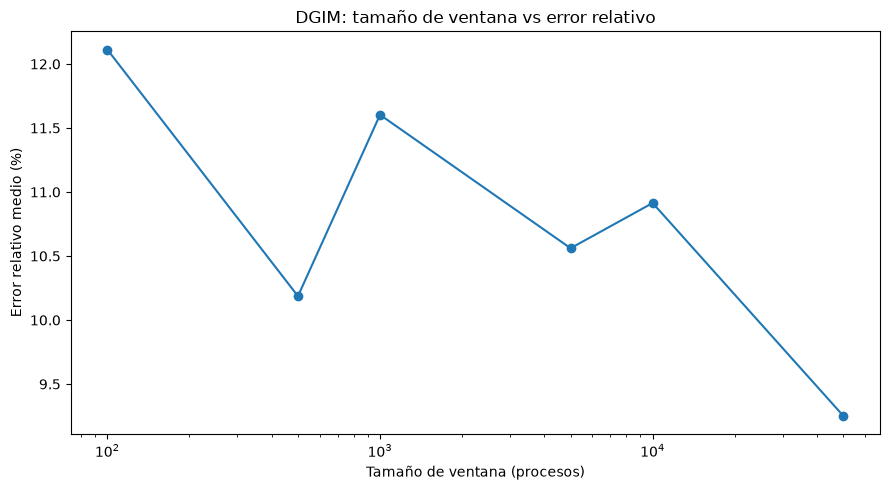

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    resultados_dgim_pd["window_size"],
    resultados_dgim_pd["error_rel_pct"],
    marker="o"
)

ax.set_xscale("log")

ax.set_title("DGIM: tamaño de ventana vs error relativo")
ax.set_xlabel("Tamaño de ventana (procesos)")
ax.set_ylabel("Error relativo medio (%)")

plt.tight_layout()
plt.show()

### Conclusión

DGIM permitió estimar el número de procesos desiertos en ventanas recientes utilizando una cantidad muy pequeña de memoria.

En las ventanas evaluadas, el error relativo medio se mantuvo aproximadamente entre 9% y 12%. Por ejemplo, para una ventana de 50,000 procesos, el conteo exacto final fue 6,069 y DGIM estimó 6,836.

El número máximo de buckets creció lentamente con el tamaño de la ventana: desde 8 buckets para W=100 hasta 24 para W=50,000. La memoria teórica estimada se mantuvo entre aproximadamente 21 y 66 bytes.

Esto muestra el principal compromiso de DGIM: sacrificar precisión en el conteo a cambio de mantener un resumen extremadamente compacto del flujo.

Para ventanas cuyo conteo exacto es cero, el error relativo no está definido; por ello, el promedio de error relativo considera únicamente observaciones con conteo exacto mayor que cero.